In [1]:
!pip install ipympl

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\Python314\python.exe -m pip install --upgrade pip


# Задача 3.2. Бильярд в прямоугольнике

## Постановка задачи

Материальная точка (бильярдный шар) движется внутри прямоугольной области
$[0,a]\times[0,b]$ и упруго отражается от границ. Требуется:

1. Записать уравнения движения и граничные условия для упругих отражений.
2. Описать **метод развёртки** и эквивалентное движение на торе.
3. Проанализировать условия периодичности и эргодичности траекторий.
4. Исследовать гамильтонову формулировку системы.
5. Построить статическую визуализацию (периодический и эргодический случаи,
   метод развёртки).
6. Создать анимацию движения шара и визуализацию метода развёртки.
7. Добавить интерактивные элементы управления.

**Система координат:** декартова, начало — левый нижний угол прямоугольника,
оси $x$ и $y$ направлены вдоль сторон $a$ и $b$ соответственно.

## Аналитическое решение

### 1. Уравнения движения внутри области

Внутри прямоугольника на шар не действуют силы, поэтому движение равномерное
и прямолинейное:

$$
\ddot{x} = 0, \qquad \ddot{y} = 0,
$$

$$
x(t) = x_0 + v_x t, \qquad y(t) = y_0 + v_y t.
$$

Скорость сохраняется по модулю: $|\vec v| = \sqrt{v_x^2+v_y^2} = \text{const}$.

### 2. Граничные условия (упругое отражение)

При упругом ударе о вертикальную стенку $x=0$ или $x=a$:

$$
v_x \to -v_x, \qquad v_y \to v_y.
$$

При ударе о горизонтальную стенку $y=0$ или $y=b$:

$$
v_y \to -v_y, \qquad v_x \to v_x.
$$

Модуль скорости сохраняется, поэтому траектория — ломаная с зеркальными
отражениями.

### 3. Метод развёртки

Идея: вместо отражений продолжим прямолинейное движение в **развёрнутой**
плоскости, отражая саму область, а не траекторию.

Пусть точка движется по прямой
$$
X(t) = x_0 + v_x t, \qquad Y(t) = y_0 + v_y t
$$
в плоскости $\mathbb R^2$. Тогда физические координаты внутри
прямоугольника получаются из развёрнутых по формулам:

$$
x(t) = a - \bigl|\,(X(t) \bmod 2a) - a\,\bigr|,
$$

$$
y(t) = b - \bigl|\,(Y(t) \bmod 2b) - b\,\bigr|.
$$

Здесь $(\cdot \bmod 2a)$ — взятие остатка по модулю $2a$. Эта операция
«треугольной волны» реализует зеркальные отражения от границ.

Эквивалентно, движение происходит на **торе** $\mathbb T^2 = S^1_a \times S^1_b$
с координатами
$$
\varphi_x = \frac{\pi X}{a}\pmod{2\pi}, \qquad
\varphi_y = \frac{\pi Y}{b}\pmod{2\pi},
$$
и развёртка является универсальным накрытием тора.

### 4. Первые интегралы и гамильтонова формулировка

Гамильтониан свободной частицы:
$$
H(p_x,p_y) = \frac{p_x^2 + p_y^2}{2m}.
$$

Движение происходит по уровню энергии $H = E = \text{const}$.
Импульс $p_x = m v_x$, $p_y = m v_y$ сохраняется между ударами; при ударе
знак соответствующей компоненты меняется. На торе импульсы становятся
**угловыми переменными**, а координаты — циклическими, поэтому система
полностью интегрируема.

### 5. Условие периодичности

Траектория замкнута (периодична), если после $N$ отражений по $x$ и $M$
отражений по $y$ точка возвращается в исходное положение с тем же направлением
скорости. Эквивалентно, на торе траектория должна быть замкнутой:

$$
\frac{v_x}{a} \, T = 2k, \qquad \frac{v_y}{b}\,T = 2l,
\qquad k,l \in \mathbb Z.
$$

Исключая $T$:

$$
\boxed{\ \frac{v_y}{v_x} = \frac{b\,l}{a\,k}\ }
$$

**Условие периодичности:** отношение $v_y/v_x$ рационально относительно $b/a$,
то есть
$$
\frac{a\,v_y}{b\,v_x} \in \mathbb Q.
$$

Если $a\,v_y / (b\,v_x) = p/q$ в несократимой форме, то траектория замкнута
и содержит ровно $p$ отражений по горизонтали и $q$ по вертикали.

### 6. Условие эргодичности

Если
$$
\frac{a\,v_y}{b\,v_x} \notin \mathbb Q,
$$
то траектория **не замыкается** и плотна в прямоугольнике: она подходит
сколь угодно близко к любой точке области (эргодичность по мере Лебега).
На торе траектория — иррациональная обмотка, равномерно распределённая.

**Угол наклона** $\alpha = \arctan(v_y/v_x)$: если $\tan\alpha$ иррационален,
траектория эргодична.

In [2]:
# ============================================================
# Задача 3.2. Бильярд в прямоугольнике
# Вспомогательные функции
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.widgets import Slider, Button
from matplotlib.patches import Rectangle
from IPython.display import HTML

# ---------- Функции метода развёртки ----------

def unfold_to_billiard(X, Y, a, b):
    """Перевод развёрнутых координат (X, Y) в физические (x, y)
    внутри прямоугольника [0, a] x [0, b] методом зеркального отражения."""
    x = a - np.abs(np.mod(X, 2 * a) - a)
    y = b - np.abs(np.mod(Y, 2 * b) - b)
    return x, y

def billiard_trajectory(x0, y0, vx, vy, a, b, T, n_points=4000):
    """Возвращает массивы (x, y) траектории шара за время T."""
    t = np.linspace(0.0, T, n_points)
    X = x0 + vx * t
    Y = y0 + vy * t
    x, y = unfold_to_billiard(X, Y, a, b)
    return t, x, y, X, Y

def is_periodic(vx, vy, a, b, tol=1e-9):
    """Проверка периодичности через рациональность a*vy/(b*vx)."""
    if abs(vx) < tol or abs(vy) < tol:
        return False
    from math import gcd
    # Представим a*vy/(b*vx) как отношение двух целых
    from fractions import Fraction
    try:
        frac = Fraction(a * vy / (b * vx)).limit_denominator(1000)
        return abs(float(frac) - a * vy / (b * vx)) < 1e-8
    except Exception:
        return False

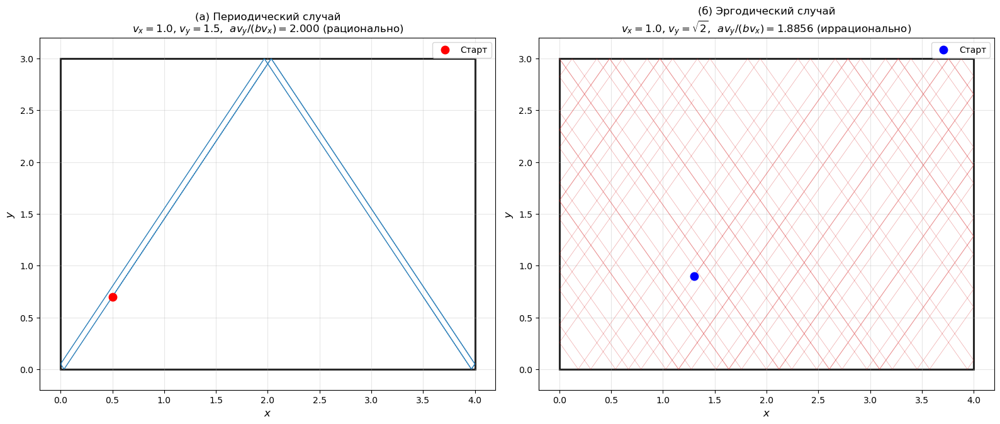

Рисунок сохранён: billiard_static.png


In [3]:
# ============================================================
# Статический график: периодический и эргодический случаи
# ============================================================
a, b = 4.0, 3.0  # стороны прямоугольника

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# ---------- (а) Периодический случай ----------
x0_p, y0_p = 0.5, 0.7
vx_p, vy_p = 1.0, 1.5      # vy/vx = 3/2; a*vy/(b*vx) = 4*1.5/(3*1) = 2 — рационально
T_p = 20.0

t_p, x_p, y_p, X_p, Y_p = billiard_trajectory(x0_p, y0_p, vx_p, vy_p,
                                              a, b, T_p, n_points=8000)
axes[0].plot(x_p, y_p, lw=0.8, color='tab:blue', alpha=0.85)
axes[0].plot(x0_p, y0_p, 'ro', ms=9, label='Старт')
axes[0].add_patch(Rectangle((0, 0), a, b, fill=False,
                            edgecolor='k', lw=2))
axes[0].set_xlim(-0.2, a + 0.2)
axes[0].set_ylim(-0.2, b + 0.2)
axes[0].set_aspect('equal')
axes[0].set_xlabel('$x$', fontsize=12)
axes[0].set_ylabel('$y$', fontsize=12)
axes[0].set_title(f'(а) Периодический случай\n'
                  f'$v_x={vx_p}$, $v_y={vy_p}$,  '
                  f'$a v_y/(b v_x) = {a*vy_p/(b*vx_p):.3f}$ (рационально)',
                  fontsize=12)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc='upper right')

# ---------- (б) Эргодический случай ----------
x0_e, y0_e = 1.3, 0.9
vx_e, vy_e = 1.0, np.sqrt(2)   # отношение иррационально
T_e = 120.0

t_e, x_e, y_e, X_e, Y_e = billiard_trajectory(x0_e, y0_e, vx_e, vy_e,
                                              a, b, T_e, n_points=40000)
axes[1].plot(x_e, y_e, lw=0.4, color='tab:red', alpha=0.5)
axes[1].plot(x0_e, y0_e, 'bo', ms=9, label='Старт')
axes[1].add_patch(Rectangle((0, 0), a, b, fill=False,
                            edgecolor='k', lw=2))
axes[1].set_xlim(-0.2, a + 0.2)
axes[1].set_ylim(-0.2, b + 0.2)
axes[1].set_aspect('equal')
axes[1].set_xlabel('$x$', fontsize=12)
axes[1].set_ylabel('$y$', fontsize=12)
axes[1].set_title(f'(б) Эргодический случай\n'
                  f'$v_x={vx_e}$, $v_y=\\sqrt{{2}}$,  '
                  f'$a v_y/(b v_x) = {a*vy_e/(b*vx_e):.4f}$ (иррационально)',
                  fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('billiard_static.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: billiard_static.png")

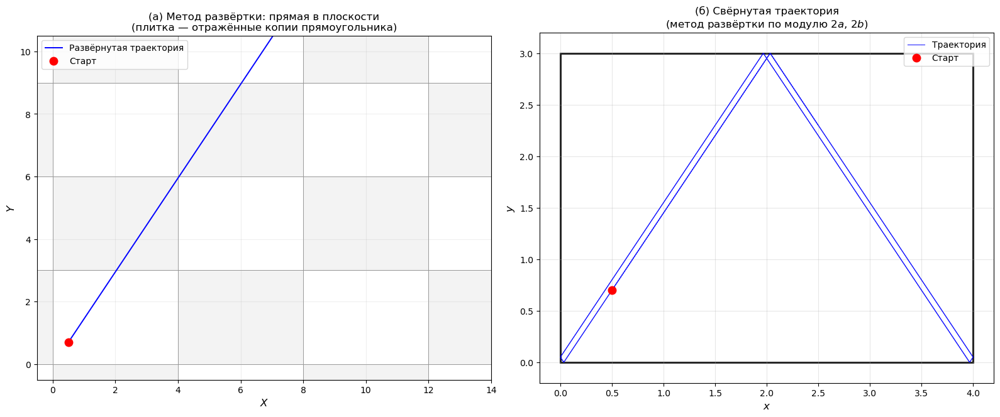

Рисунок сохранён: billiard_unfold.png


In [4]:
# ============================================================
# Визуализация метода развёртки
# ============================================================
a_d, b_d = 4.0, 3.0
x0_d, y0_d = 0.5, 0.7
vx_d, vy_d = 1.0, 1.5
T_d = 18.0

t_d, x_d, y_d, X_d, Y_d = billiard_trajectory(x0_d, y0_d, vx_d, vy_d,
                                              a_d, b_d, T_d, n_points=6000)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# ---------- (а) Прямая в развёрнутой плоскости ----------
# Рисуем «плитку» из отражённых прямоугольников
for i in range(-1, 4):
    for j in range(-1, 4):
        color = 'white' if (i + j) % 2 == 0 else '#f0f0f0'
        axes[0].add_patch(Rectangle((i * a_d, j * b_d), a_d, b_d,
                                    facecolor=color, edgecolor='gray',
                                    lw=0.6, alpha=0.8))

axes[0].plot(X_d, Y_d, 'b-', lw=1.4, label='Развёрнутая траектория')
axes[0].plot(x0_d, y0_d, 'ro', ms=9, label='Старт')
axes[0].set_xlim(-0.5, 3.5 * a_d)
axes[0].set_ylim(-0.5, 3.5 * b_d)
axes[0].set_aspect('equal')
axes[0].set_xlabel('$X$', fontsize=12)
axes[0].set_ylabel('$Y$', fontsize=12)
axes[0].set_title('(а) Метод развёртки: прямая в плоскости\n'
                  '(плитка — отражённые копии прямоугольника)', fontsize=12)
axes[0].grid(True, alpha=0.2)
axes[0].legend(loc='upper left')

# ---------- (б) Свёрнутая траектория в исходном прямоугольнике ----------
axes[1].plot(x_d, y_d, 'b-', lw=0.8, alpha=0.85, label='Траектория')
axes[1].plot(x0_d, y0_d, 'ro', ms=9, label='Старт')
axes[1].add_patch(Rectangle((0, 0), a_d, b_d, fill=False,
                            edgecolor='k', lw=2))
axes[1].set_xlim(-0.2, a_d + 0.2)
axes[1].set_ylim(-0.2, b_d + 0.2)
axes[1].set_aspect('equal')
axes[1].set_xlabel('$x$', fontsize=12)
axes[1].set_ylabel('$y$', fontsize=12)
axes[1].set_title('(б) Свёрнутая траектория\n(метод развёртки по модулю $2a$, $2b$)',
                  fontsize=12)
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig('billiard_unfold.png', dpi=150, bbox_inches='tight')
plt.show()
print("Рисунок сохранён: billiard_unfold.png")

## Анимация движения шара

Используем `matplotlib.animation.FuncAnimation`. На анимации:

- **левая панель** — исходный прямоугольник с движущейся точкой, её следом
  и мгновенным вектором скорости;
- **правая панель** — метод развёртки: луч в плоскости, «плитка» из
  отражённых прямоугольников, подсветка активной ячейки.

Параметры (стороны, начальное положение, скорости) задаются в коде.
Для рационального отношения $v_y/v_x$ траектория замыкается, для
иррационального — заполняет область.

In [5]:
# ============================================================
# Анимация: бильярд + метод развёртки
# ============================================================
a_an, b_an = 4.0, 3.0
x0_an, y0_an = 0.6, 0.8
vx_an, vy_an = 1.0, np.sqrt(2)   # иррациональное отношение — эргодический случай
T_an = 30.0
n_frames = 600

t_an = np.linspace(0.0, T_an, n_frames)
X_an = x0_an + vx_an * t_an
Y_an = y0_an + vy_an * t_an
x_an, y_an = unfold_to_billiard(X_an, Y_an, a_an, b_an)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(16, 6.5))

# ---------- Левая панель: бильярд ----------
axL.set_xlim(-0.3, a_an + 0.3)
axL.set_ylim(-0.3, b_an + 0.3)
axL.set_aspect('equal')
axL.set_xlabel('$x$', fontsize=12)
axL.set_ylabel('$y$', fontsize=12)
axL.set_title('Бильярд в прямоугольнике', fontsize=13)
axL.grid(True, alpha=0.3)
axL.add_patch(Rectangle((0, 0), a_an, b_an, fill=False, edgecolor='k', lw=2))

trail_L, = axL.plot([], [], '-', color='tab:blue', lw=1.0, alpha=0.75)
point_L, = axL.plot([], [], 'ro', ms=11, zorder=5)
quiver_L = axL.quiver([0], [0], [0], [0], angles='xy',
                      scale_units='xy', scale=1.0, color='darkred',
                      width=0.006, zorder=6)

info_L = axL.text(0.02, 0.98, '', transform=axL.transAxes,
                  va='top', ha='left', fontsize=10, family='monospace',
                  bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))

# ---------- Правая панель: развёртка ----------
n_tiles_x, n_tiles_y = 4, 4
for i in range(n_tiles_x):
    for j in range(n_tiles_y):
        color = 'white' if (i + j) % 2 == 0 else '#f5f5f5'
        axR.add_patch(Rectangle((i * a_an, j * b_an), a_an, b_an,
                                facecolor=color, edgecolor='gray',
                                lw=0.6, alpha=0.9))

axR.set_xlim(-0.5, n_tiles_x * a_an + 0.5)
axR.set_ylim(-0.5, n_tiles_y * b_an + 0.5)
axR.set_aspect('equal')
axR.set_xlabel('$X$', fontsize=12)
axR.set_ylabel('$Y$', fontsize=12)
axR.set_title('Метод развёртки: прямая в плоскости', fontsize=13)
axR.grid(True, alpha=0.2)

ray_R, = axR.plot([], [], 'b-', lw=1.4, alpha=0.85)
point_R, = axR.plot([], [], 'ro', ms=9, zorder=5)

# Активная ячейка
active_tile = Rectangle((0, 0), a_an, b_an, facecolor='yellow',
                        alpha=0.25, edgecolor='orange', lw=1.5, zorder=1)
axR.add_patch(active_tile)

# ---------- Функции анимации ----------
def init_anim():
    trail_L.set_data([], [])
    point_L.set_data([], [])
    ray_R.set_data([], [])
    point_R.set_data([], [])
    info_L.set_text('')
    return trail_L, point_L, ray_R, point_R, info_L, active_tile

def update_anim(frame):
    # Левая панель
    trail_L.set_data(x_an[:frame + 1], y_an[:frame + 1])
    point_L.set_data([x_an[frame]], [y_an[frame]])

    # Мгновенная скорость: знак меняется при отражениях
    cur_x = x_an[frame]
    cur_X = X_an[frame]
    cur_Y = Y_an[frame]
    # Определяем знак vx: чётное число отражений — vx>0
    kx = int(np.floor(cur_X / a_an))  # номер «полосы» по x
    ky = int(np.floor(cur_Y / b_an))
    vx_cur = vx_an * ((-1) ** kx)
    vy_cur = vy_an * ((-1) ** ky)

    quiver_L.set_offsets([[cur_x, y_an[frame]]])
    quiver_L.set_UVC([vx_cur], [vy_cur])

    # Правая панель
    ray_R.set_data(X_an[:frame + 1], Y_an[:frame + 1])
    point_R.set_data([cur_X], [cur_Y])

    # Активная ячейка
    tile_x = np.floor(cur_X / a_an) * a_an
    tile_y = np.floor(cur_Y / b_an) * b_an
    active_tile.set_xy((tile_x, tile_y))

    # Информация
    info_L.set_text(
        f"t  = {t_an[frame]:6.3f}\n"
        f"x  = {cur_x:6.3f}\n"
        f"y  = {y_an[frame]:6.3f}\n"
        f"vx = {vx_cur:+6.3f}\n"
        f"vy = {vy_cur:+6.3f}"
    )
    return trail_L, point_L, ray_R, point_R, info_L, active_tile

anim = animation.FuncAnimation(
    fig, update_anim, frames=n_frames, init_func=init_anim,
    interval=30, blit=True, repeat=True
)
plt.close(fig)
HTML(anim.to_jshtml())

Animation size has reached 21001737 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


## Интерактивная анимация с ползунками

Требуется `ipympl` (см. задачу 3.1). Элементы:

- ползунок $a$ — ширина прямоугольника,
- ползунок $b$ — высота прямоугольника,
- ползунок $v_y/v_x$ — отношение скоростей (рациональное → периодика,
  иррациональное → эргодичность),
- кнопка **Pause/Play**,
- кнопка **Reset**.

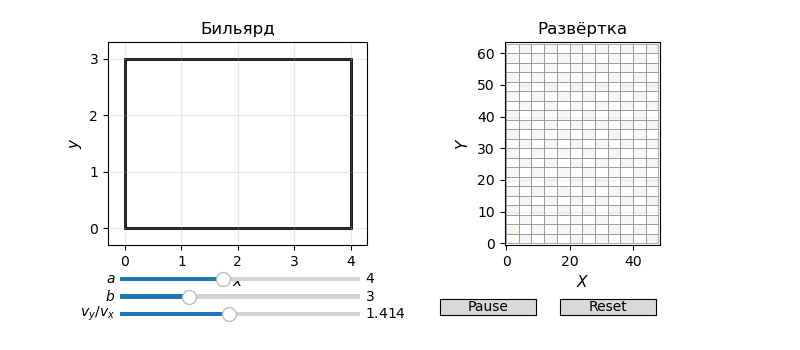

In [11]:
# ============================================================
# Задача 3.2. Бильярд в прямоугольнике
# Интерактивная анимация с ползунками (JupyterLab 4 + ipympl)
# ============================================================
%matplotlib ipympl

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider, Button
from matplotlib.patches import Rectangle
import matplotlib.animation as animation


# ------------------------------------------------------------
# 1. Функция метода развёртки
# ------------------------------------------------------------
def unfold_to_billiard(X, Y, a, b):
    """Перевод развёрнутых координат (X, Y) в физические (x, y)
    внутри прямоугольника [0, a] x [0, b] методом зеркального отражения."""
    x = a - np.abs(np.mod(X, 2.0 * a) - a)
    y = b - np.abs(np.mod(Y, 2.0 * b) - b)
    return x, y


# ------------------------------------------------------------
# 2. Начальные параметры системы
# ------------------------------------------------------------
state = {
    'a': 4.0,          # ширина прямоугольника
    'b': 3.0,          # высота прямоугольника
    'x0': 0.6,         # начальная координата x
    'y0': 0.8,         # начальная координата y
    'vx': 1.0,         # горизонтальная скорость
    'vy': np.sqrt(2),  # вертикальная скорость (иррационально -> эргодический случай)
    'T': 40.0,         # время моделирования
    'n_frames': 800,   # число кадров анимации
}

# Пересчёт траектории по текущим параметрам
state['t'] = np.linspace(0.0, state['T'], state['n_frames'])
state['X'] = state['x0'] + state['vx'] * state['t']
state['Y'] = state['y0'] + state['vy'] * state['t']
state['x'], state['y'] = unfold_to_billiard(state['X'], state['Y'],
                                            state['a'], state['b'])


# ------------------------------------------------------------
# 3. Фигура: слева бильярд, справа метод развёртки
# ------------------------------------------------------------
fig, (axL, axR) = plt.subplots(1, 2, figsize=(8, 3.5))
plt.subplots_adjust(bottom=0.30, wspace=0.25)

# ---------- Левая панель: бильярд ----------
axL.set_aspect('equal')
axL.set_xlabel('$x$', fontsize=11)
axL.set_ylabel('$y$', fontsize=11)
axL.set_title('Бильярд', fontsize=12)
axL.grid(True, alpha=0.3)
axL.set_xlim(-0.3, state['a'] + 0.3)
axL.set_ylim(-0.3, state['b'] + 0.3)

rect_L = Rectangle((0.0, 0.0), state['a'], state['b'],
                   fill=False, edgecolor='k', lw=2)
axL.add_patch(rect_L)

trail_L, = axL.plot([], [], '-', color='tab:blue', lw=1.0, alpha=0.75)
point_L, = axL.plot([], [], 'ro', ms=10, zorder=5)
info_L = axL.text(0.02, 0.98, '', transform=axL.transAxes,
                  va='top', ha='left', fontsize=9, family='monospace',
                  bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))

# ---------- Правая панель: развёртка ----------
axR.set_aspect('equal')
axR.set_xlabel('$X$', fontsize=11)
axR.set_ylabel('$Y$', fontsize=11)
axR.set_title('Развёртка', fontsize=12)
axR.grid(True, alpha=0.2)


def draw_tiles():
    """Перерисовать «плитку» отражённых копий прямоугольника."""
    # Удаляем старые прямоугольники (кроме активной ячейки)
    for p in list(axR.patches):
        if p is not active_tile:
            p.remove()
    n_x = max(2, int(np.ceil(state['X'].max() / state['a'])) + 1)
    n_y = max(2, int(np.ceil(state['Y'].max() / state['b'])) + 1)
    for i in range(n_x):
        for j in range(n_y):
            color = 'white' if (i + j) % 2 == 0 else '#f5f5f5'
            axR.add_patch(Rectangle((i * state['a'], j * state['b']),
                                    state['a'], state['b'],
                                    facecolor=color, edgecolor='gray',
                                    lw=0.5, alpha=0.9))
    axR.set_xlim(-0.5, n_x * state['a'] + 0.5)
    axR.set_ylim(-0.5, n_y * state['b'] + 0.5)


ray_R, = axR.plot([], [], 'b-', lw=1.3, alpha=0.85)
point_R, = axR.plot([], [], 'ro', ms=9, zorder=5)

# Активная ячейка развёртки (подсветка)
active_tile = Rectangle((0.0, 0.0), state['a'], state['b'],
                        facecolor='yellow', alpha=0.25,
                        edgecolor='orange', lw=1.5, zorder=1)
axR.add_patch(active_tile)

draw_tiles()


# ------------------------------------------------------------
# 4. Пересчёт траектории при изменении параметров
# ------------------------------------------------------------
def rebuild():
    state['t'] = np.linspace(0.0, state['T'], state['n_frames'])
    state['X'] = state['x0'] + state['vx'] * state['t']
    state['Y'] = state['y0'] + state['vy'] * state['t']
    state['x'], state['y'] = unfold_to_billiard(state['X'], state['Y'],
                                                state['a'], state['b'])

    # Обновляем рамку слева
    rect_L.set_width(state['a'])
    rect_L.set_height(state['b'])
    axL.set_xlim(-0.3, state['a'] + 0.3)
    axL.set_ylim(-0.3, state['b'] + 0.3)

    # Обновляем активную ячейку справа
    active_tile.set_width(state['a'])
    active_tile.set_height(state['b'])

    draw_tiles()
    fig.canvas.draw_idle()


# ------------------------------------------------------------
# 5. Функции анимации
# ------------------------------------------------------------
def init_anim():
    """Инициализация анимации (пустые объекты)."""
    trail_L.set_data([], [])
    point_L.set_data([], [])
    ray_R.set_data([], [])
    point_R.set_data([], [])
    info_L.set_text('')
    return trail_L, point_L, ray_R, point_R, info_L, active_tile


def update_anim(frame):
    """Обновление кадра анимации."""
    n = len(state['x'])
    frame = frame % n

    # Левая панель — бильярд
    trail_L.set_data(state['x'][:frame + 1], state['y'][:frame + 1])
    point_L.set_data([state['x'][frame]], [state['y'][frame]])

    # Правая панель — развёртка
    ray_R.set_data(state['X'][:frame + 1], state['Y'][:frame + 1])
    point_R.set_data([state['X'][frame]], [state['Y'][frame]])

    # Определяем текущие знаки скоростей по номеру «полосы»
    kx = int(np.floor(state['X'][frame] / state['a']))
    ky = int(np.floor(state['Y'][frame] / state['b']))
    vx_cur = state['vx'] * ((-1) ** kx)
    vy_cur = state['vy'] * ((-1) ** ky)

    # Активная ячейка развёртки
    active_tile.set_xy((kx * state['a'], ky * state['b']))

    # Информационная панель
    info_L.set_text(
        f"t  = {state['t'][frame]:6.2f}\n"
        f"x  = {state['x'][frame]:6.2f}\n"
        f"y  = {state['y'][frame]:6.2f}\n"
        f"vx = {vx_cur:+6.2f}\n"
        f"vy = {vy_cur:+6.2f}"
    )
    return trail_L, point_L, ray_R, point_R, info_L, active_tile


anim = animation.FuncAnimation(
    fig, update_anim,
    frames=state['n_frames'],
    init_func=init_anim,
    interval=25,
    blit=False,
    repeat=True,
)


# ------------------------------------------------------------
# 6. Ползунки параметров
# ------------------------------------------------------------
ax_a = plt.axes([0.15, 0.19, 0.30, 0.025])
ax_b = plt.axes([0.15, 0.14, 0.30, 0.025])
ax_r = plt.axes([0.15, 0.09, 0.30, 0.025])

sl_a = Slider(ax_a, '$a$', 1.0, 8.0, valinit=state['a'], valstep=0.1)
sl_b = Slider(ax_b, '$b$', 1.0, 8.0, valinit=state['b'], valstep=0.1)
sl_r = Slider(ax_r, '$v_y/v_x$', 0.1, 3.0,
              valinit=state['vy'] / state['vx'], valstep=0.001)


def on_change(val):
    """Обработчик изменения любого ползунка."""
    state['a'] = sl_a.val
    state['b'] = sl_b.val
    state['vx'] = 1.0
    state['vy'] = sl_r.val
    rebuild()


sl_a.on_changed(on_change)
sl_b.on_changed(on_change)
sl_r.on_changed(on_change)


# ------------------------------------------------------------
# 7. Кнопки Pause / Reset
# ------------------------------------------------------------
ax_play = plt.axes([0.55, 0.10, 0.12, 0.045])
ax_reset = plt.axes([0.70, 0.10, 0.12, 0.045])

btn_play = Button(ax_play, 'Pause')
btn_reset = Button(ax_reset, 'Reset')

is_playing = {'value': True}


def toggle_play(event):
    """Пауза / воспроизведение."""
    if is_playing['value']:
        anim.pause()
        btn_play.label.set_text('Play')
        is_playing['value'] = False
    else:
        anim.resume()
        btn_play.label.set_text('Pause')
        is_playing['value'] = True


def reset(event):
    """Сброс анимации в начало."""
    anim.frame_seq = anim.new_frame_seq()
    if not is_playing['value']:
        anim.resume()
        btn_play.label.set_text('Pause')
        is_playing['value'] = True


btn_play.on_clicked(toggle_play)
btn_reset.on_clicked(reset)


# ------------------------------------------------------------
# 8. Запуск
# ------------------------------------------------------------
plt.show()

In [7]:
# ============================================================
# Анализ условий периодичности и эргодичности
# ============================================================
from fractions import Fraction

a, b = 4.0, 3.0

test_cases = [
    (1.0, 1.0,   "рациональное 1:1"),
    (1.0, 1.5,   "рациональное 2:3"),
    (1.0, 0.75,  "рациональное 4:3"),
    (1.0, np.sqrt(2),  "иррациональное √2"),
    (1.0, np.pi,       "иррациональное π"),
    (1.0, (1 + np.sqrt(5)) / 2, "иррациональное φ"),
]

print(f"{'vx':>6} {'vy':>10} {'a*vy/(b*vx)':>14}  {'период':>8}  режим")
print("-" * 65)
for vx, vy, comment in test_cases:
    ratio = a * vy / (b * vx)
    frac = Fraction(ratio).limit_denominator(50)
    periodic = abs(float(frac) - ratio) < 1e-8
    if periodic:
        # Минимальный период: T = 2a*k/vx при условии, что 2b*l/vy = T
        # a*vy/(b*vx) = p/q => k = q, l = p
        q, p = frac.denominator, frac.numerator
        T = 2 * a * q / vx
        mode = f"период T={T:.3f}"
    else:
        mode = "эргодический"
    print(f"{vx:>6.2f} {vy:>10.4f} {ratio:>14.4f}  {mode:>14}  {comment}")

    vx         vy    a*vy/(b*vx)    период  режим
-----------------------------------------------------------------
  1.00     1.0000         1.3333  период T=24.000  рациональное 1:1
  1.00     1.5000         2.0000  период T=8.000  рациональное 2:3
  1.00     0.7500         1.0000  период T=8.000  рациональное 4:3
  1.00     1.4142         1.8856    эргодический  иррациональное √2
  1.00     3.1416         4.1888    эргодический  иррациональное π
  1.00     1.6180         2.1574    эргодический  иррациональное φ


## Выводы

1. **Уравнения движения.** Внутри прямоугольника шар движется равномерно
   и прямолинейно. Упругое отражение меняет знак нормальной компоненты
   скорости, сохраняя её модуль.

2. **Метод развёртки.** Отражения заменяются продолжением прямой в плоскости
   $\mathbb R^2$ и «свёрткой» по модулю $2a$, $2b$. Эквивалентная система —
   свободное движение на торе $\mathbb T^2$, что делает задачу полностью
   интегрируемой (гамильтонов формализм, $H = (p_x^2+p_y^2)/2m$).

3. **Условие периодичности.**
   $$
   \frac{a\,v_y}{b\,v_x} \in \mathbb Q.
   $$
   При этом траектория замкнута; число отражений по горизонтали и вертикали
   равно соответственно $q$ и $p$, где $p/q$ — несократимая дробь.

4. **Условие эргодичности.** Если $a\,v_y / (b\,v_x)$ иррационально,
   траектория не замыкается и плотна в прямоугольнике — типичное поведение
   интегрируемой, но не периодической системы.

5. **Визуализация.** Построены:
   - статический график периодического и эргодического случаев
     (`billiard_static.png`);
   - иллюстрация метода развёртки с «плиткой» (`billiard_unfold.png`);
   - анимация движения шара + развёртки;
   - интерактивная версия с ползунками $a$, $b$, $v_y/v_x$ и кнопками
     Pause / Play / Reset.